<a href="https://colab.research.google.com/github/SaraLarkem/ireland-fuel-grocery-viz/blob/main/notebooks/04_External_Shocks_and_Event_Impact.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **External Shocks and Event Impact**

## 1. Overview

This notebook looks at how petrol, diesel and food prices changed during selected major events.
It compares event periods with months outside the selected event windows and looks at monthly percentage changes, maximum monthly changes and price volatility.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# get the cleaned data from GitHub
data_url = "https://raw.githubusercontent.com/SaraLarkem/ireland-fuel-grocery-viz/main/data/cleaned_fuel_grocery_data.csv"

# load the data
df = pd.read_csv(data_url)

# just checking the first few rows
df.head()

,Month,Diesel,Food and non-alcoholic beverages,Petrol,Month_DT,Month_Diff
0,2016 January,65.0,90.7,72.8,2016-01-01,NaN
1,2016 February,61.1,90.0,70.5,2016-02-01,31 days
2,2016 March,61.9,90.3,70.0,2016-03-01,29 days
3,2016 April,64.2,90.0,73.1,2016-04-01,31 days
4,2016 May,65.3,90.0,74.7,2016-05-01,30 days


In [2]:
# make sure the date column is read as a date
df["Month_DT"] = pd.to_datetime(df["Month_DT"])

# check the date range
print("First month:", df["Month_DT"].min())
print("Last month:", df["Month_DT"].max())

First month: 2016-01-01 00:00:00
Last month: 2026-09-01 00:00:00


## 2. Event Periods

The following date ranges were selected to look at price changes during each event.

In [3]:
# event periods used for the analysis
events = {
    "Post-COVID supply issues": ("2021-01-01", "2021-12-31"),
    "Ukraine invasion": ("2022-02-01", "2022-06-30"),
    "ECB rate hikes": ("2022-07-01", "2023-09-30"),
    "Strait of Hormuz disruption": ("2026-03-01", "2026-04-30")
}

events

{'Post-COVID supply issues': ('2021-01-01', '2021-12-31'),
 'Ukraine invasion': ('2022-02-01', '2022-06-30'),
 'ECB rate hikes': ('2022-07-01', '2023-09-30'),
 'Strait of Hormuz disruption': ('2026-03-01', '2026-04-30')}

Sources for event dates:

- [ECB – Supply chain disruptions](https://www.ecb.europa.eu/press/economic-bulletin/html/eb202108.en.html)
- [European Council – Russia's invasion of Ukraine](https://www.consilium.europa.eu/en/press/press-releases/2022/02/24/european-council-conclusions-24-february-2022/)
- [ECB – Interest rate changes](https://www.ecb.europa.eu/ecb-and-you/explainers/html/interest-rates-changes.en.html)
- [Reuters – Strait of Hormuz disruption](https://www.reuters.com/world/middle-east/see-tanker-traffic-strait-hormuz-come-standstill-2026-03-05/)

## 3. Price Trends During Event Periods

This chart shows how petrol, diesel and food prices moved over time, with the selected event periods highlighted

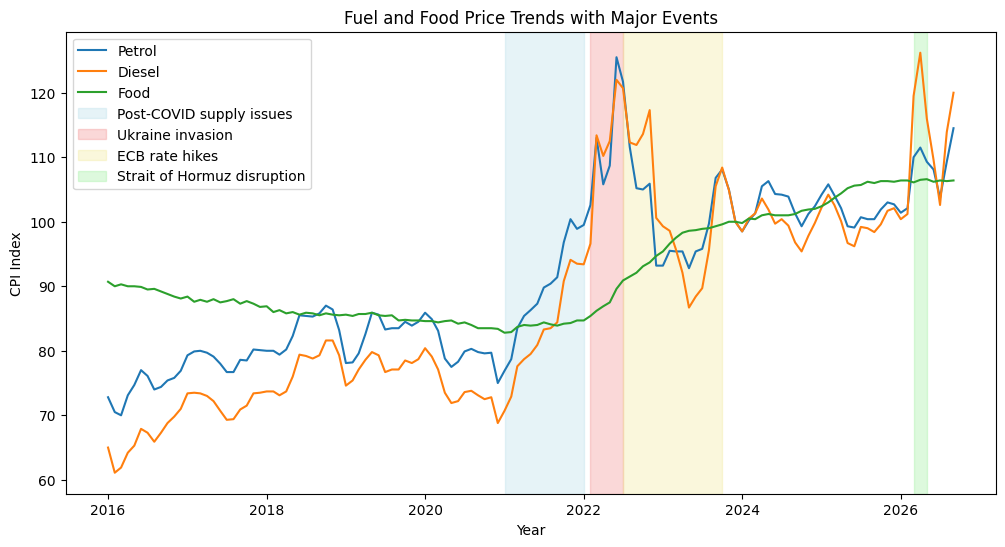

In [4]:
# plot the trends with event periods
plt.figure(figsize=(12, 6))

plt.plot(df["Month_DT"], df["Petrol"], label="Petrol")
plt.plot(df["Month_DT"], df["Diesel"], label="Diesel")
plt.plot(df["Month_DT"], df["Food and non-alcoholic beverages"], label="Food")

# colours for each event
event_colours = ["lightblue", "lightcoral", "khaki", "lightgreen"]

# add the event periods
for (event, dates), colour in zip(events.items(), event_colours):
    start = pd.to_datetime(dates[0])
    end = pd.to_datetime(dates[1])
    plt.axvspan(start, end, color=colour, alpha=0.3, label=event)

plt.title("Fuel and Food Price Trends with Major Events")
plt.xlabel("Year")
plt.ylabel("CPI Index")
plt.legend()

plt.show()

The chart shows sharper fuel price movements during some event periods, while food prices changed more gradually.

## 4. Monthly Price Changes

We calculate the month-to-month percentage change for petrol, diesel and food indices to compare how much they changed across different periods.

In [5]:
# calculate monthly price changes
df["Petrol_change"] = df["Petrol"].pct_change() * 100
df["Diesel_change"] = df["Diesel"].pct_change() * 100
df["Food_change"] = df["Food and non-alcoholic beverages"].pct_change() * 100

# check the results
df[["Month_DT", "Petrol_change", "Diesel_change", "Food_change"]].head()

,Month_DT,Petrol_change,Diesel_change,Food_change
0,2016-01-01,NaN,NaN,NaN
1,2016-02-01,-3.159341,-6.000000,-0.771775
2,2016-03-01,-0.709220,1.309329,0.333333
3,2016-04-01,4.428571,3.715670,-0.332226
4,2016-05-01,2.188782,1.713396,0.000000


## 5. Event and Normal Periods

First, all months are labelled as "Normal" If a month is within one of the selected event periods, the label is changed to the event name. This groups the months so we can compare normal periods with the event periods.

In [6]:
# start by marking all months as normal
df["Period"] = "Normal"

# mark the months that fall inside an event period
for event, dates in events.items():
    start = pd.to_datetime(dates[0])
    end = pd.to_datetime(dates[1])

    df.loc[
        (df["Month_DT"] >= start) & (df["Month_DT"] <= end),
        "Period"
    ] = event

# check the result
df[["Month_DT", "Period"]].tail(20)

,Month_DT,Period
109,2025-02-01,Normal
110,2025-03-01,Normal
111,2025-04-01,Normal
112,2025-05-01,Normal
113,2025-06-01,Normal
114,2025-07-01,Normal
115,2025-08-01,Normal
116,2025-09-01,Normal
117,2025-10-01,Normal
118,2025-11-01,Normal


We also check how many months are included in each period, so we know how much data is being compared for each event.

In [7]:
# check how many months are in each period
df["Period"].value_counts()

,count
Period,
Normal,95
ECB rate hikes,15
Post-COVID supply issues,12
Ukraine invasion,5
Strait of Hormuz disruption,2


## 6. Average Monthly Changes

We group the monthly changes by period and calculate the average change for petrol, diesel and food
this helps us compare how prices moved during normal and event periods.

In [8]:
# average monthly price change for each period
average_changes = df.groupby("Period")[
    ["Petrol_change", "Diesel_change", "Food_change"]
].mean().round(2)

average_changes

,Petrol_change,Diesel_change,Food_change
Period,,,
ECB rate hikes,-0.96,-0.80,0.69
Normal,0.04,0.00,-0.02
Post-COVID supply issues,2.35,2.61,0.13
Strait of Hormuz disruption,4.55,11.84,0.05
Ukraine invasion,5.02,5.71,1.13


## 7. Maximum Monthly Changes

We identify the largest monthly change within each period to compare the strongest price movements

In [9]:
# find the biggest monthly change in each period
max_monthly_change = df.groupby("Period")[
    ["Petrol_change", "Diesel_change", "Food_change"]
].agg(lambda x: x.abs().max()).round(2)

max_monthly_change

,Petrol_change,Diesel_change,Food_change
Period,,,
ECB rate hikes,11.99,14.24,1.45
Normal,6.13,11.01,1.04
Post-COVID supply issues,6.10,7.58,0.97
Strait of Hormuz disruption,7.74,18.08,0.38
Ukraine invasion,15.46,17.39,2.40


We compare the maximum monthly changes in each event period with the normal period to see how much higher or lower they were.

In [10]:
# compare maximum monthly changes with the normal period
normal_max_change = max_monthly_change.loc["Normal"]

max_change_comparison = max_monthly_change.subtract(normal_max_change).round(2)

max_change_comparison

,Petrol_change,Diesel_change,Food_change
Period,,,
ECB rate hikes,5.86,3.23,0.41
Normal,0.00,0.00,0.00
Post-COVID supply issues,-0.03,-3.43,-0.07
Strait of Hormuz disruption,1.61,7.07,-0.66
Ukraine invasion,9.33,6.38,1.36


The Ukraine invasion period had the largest increase in maximum monthly change compared with the normal period, especially for petrol and diesel. The Strait of Hormuz period also had a high diesel change, but it only contains two months of data.

## 8. Price Volatility

We calculate the volatility of the monthly changes in each period to compare how stable or variable the price movements were.

In [11]:
# calculate price volatility for each period
volatility = df.groupby("Period")[
    ["Petrol_change", "Diesel_change", "Food_change"]
].std().round(2)

volatility

,Petrol_change,Diesel_change,Food_change
Period,,,
ECB rate hikes,4.86,5.80,0.42
Normal,2.23,2.80,0.39
Post-COVID supply issues,2.16,2.41,0.45
Strait of Hormuz disruption,4.51,8.82,0.47
Ukraine invasion,8.27,7.67,0.71


Here, we compare the volatility in each event period with the normal period to see how much more or less variable the price movements were.

In [12]:
# compare volatility with the normal period
normal_volatility = volatility.loc["Normal"]

volatility_comparison = volatility.subtract(normal_volatility).round(2)

volatility_comparison

,Petrol_change,Diesel_change,Food_change
Period,,,
ECB rate hikes,2.63,3.00,0.03
Normal,0.00,0.00,0.00
Post-COVID supply issues,-0.07,-0.39,0.06
Strait of Hormuz disruption,2.28,6.02,0.08
Ukraine invasion,6.04,4.87,0.32


## 9. Visual Comparison

The following charts compare the average monthly change, price volatility and maximum monthly change across the different periods.

### Average Monthly Change

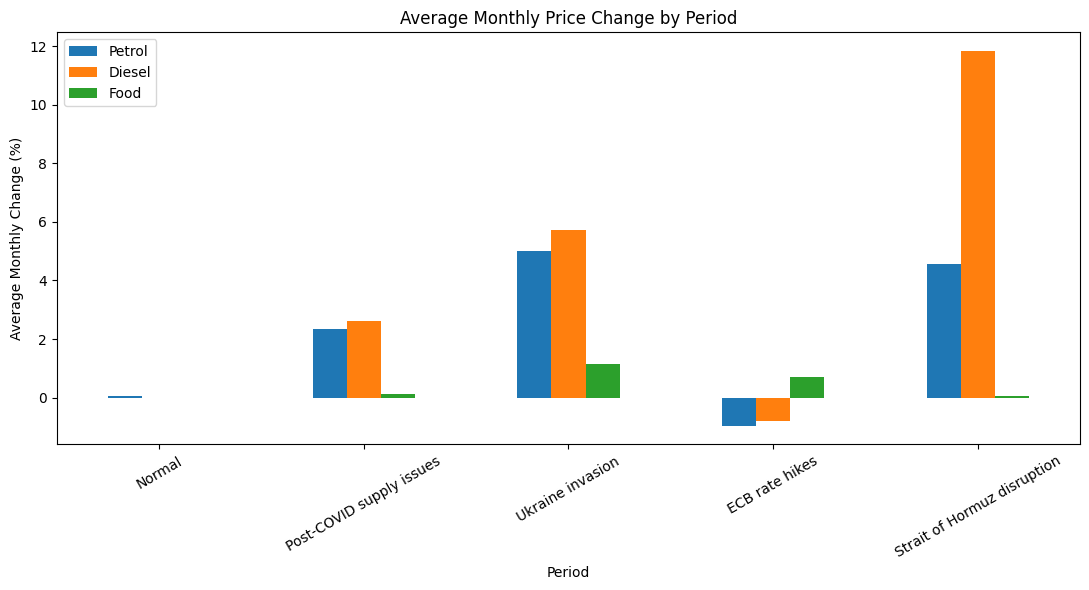

In [13]:
# put the periods in a clearer order
period_order = [
    "Normal",
    "Post-COVID supply issues",
    "Ukraine invasion",
    "ECB rate hikes",
    "Strait of Hormuz disruption"
]

average_changes_ordered = average_changes.loc[period_order]

# plot the average monthly changes
average_changes_ordered.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Average Monthly Price Change by Period")
plt.xlabel("Period")
plt.ylabel("Average Monthly Change (%)")
plt.xticks(rotation=30)
plt.legend(["Petrol", "Diesel", "Food"])

plt.tight_layout()
plt.show()

The chart shows larger average monthly fuel changes during the Ukraine invasion and Strait of Hormuz periods, while food changes were much smaller.

### Price Volatility
The average monthly change shows the overall direction and size of the changes, while the next chart shows how much the monthly changes varied within each period.

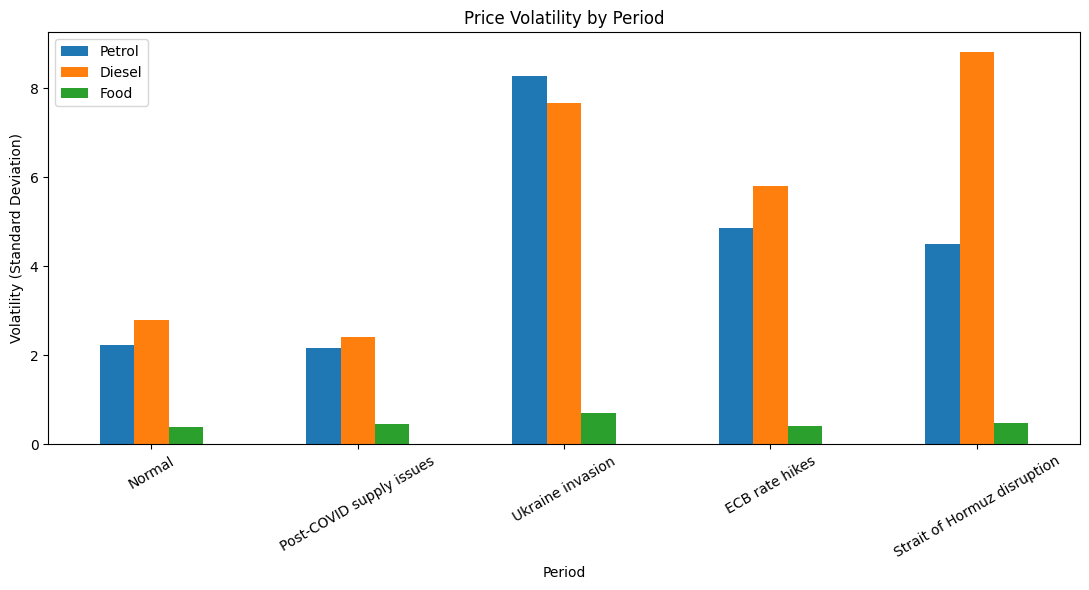

In [14]:
# plot price volatility for each period
volatility_ordered = volatility.loc[period_order]

volatility_ordered.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Price Volatility by Period")
plt.xlabel("Period")
plt.ylabel("Volatility (Standard Deviation)")
plt.xticks(rotation=30)
plt.legend(["Petrol", "Diesel", "Food"])

plt.tight_layout()
plt.show()

Fuel prices were more volatile during the Ukraine invasion and Strait of Hormuz periods, while food prices remained more stable.

### Maximum Monthly Change

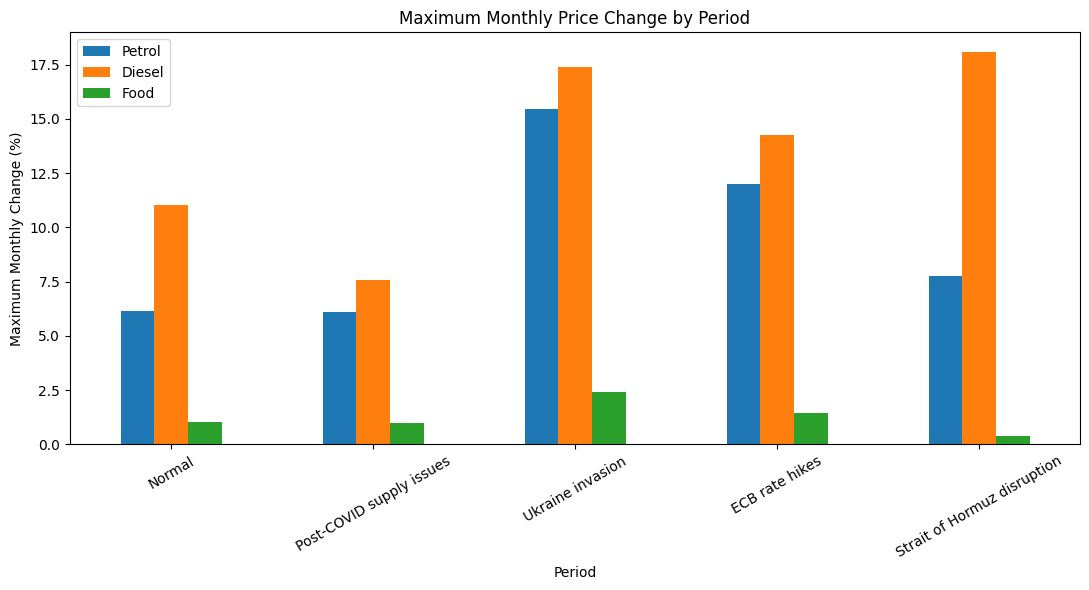

In [15]:
# plot the maximum monthly changes for each period
max_monthly_change_ordered = max_monthly_change.loc[period_order]

max_monthly_change_ordered.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Maximum Monthly Price Change by Period")
plt.xlabel("Period")
plt.ylabel("Maximum Monthly Change (%)")
plt.xticks(rotation=30)
plt.legend(["Petrol", "Diesel", "Food"])

plt.tight_layout()
plt.show()

The largest monthly fuel changes occurred during the Ukraine invasion and Strait of Hormuz periods. Food prices changed less sharply than petrol and diesel.